In [14]:
# Import required libraries for API calls and environment configuration
# If needed:  pip install groq python-dotenv requests
import json  # For parsing and serializing JSON objects
import requests  # For making HTTP requests to external APIs
import os  # For accessing environment variables
from groq import Groq  # Groq API client for LLM interactions
from dotenv import load_dotenv  # For loading environment variables from .env file
from IPython.display import Markdown, display  # For displaying formatted output in Jupyter notebooks
import base64
import mimetypes
from pathlib import Path

# Load environment variables from .env file (contains API keys and sensitive data)
load_dotenv()

# Initialize the Groq client with API key from environment variables
client = Groq(api_key=os.getenv("GROQ_API_KEY"))

# Specify the model to use for API calls
# The 70b model handles multi-step tool use more reliably than 8b
model = "openai/gpt-oss-120b"

In [15]:
import base64
import mimetypes
import shutil
import uuid
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path


MIME_TYPE_MAP = {
    ".pdf": "application/pdf",
    ".txt": "text/plain",
    ".md": "text/plain",
    ".py": "text/plain",
    ".js": "text/plain",
    ".html": "text/plain",
    ".css": "text/plain",
    ".csv": "text/csv",
    ".json": "application/json",
    ".xml": "application/xml",
    ".xlsx": "application/vnd.openxmlformats-officedocument.spreadsheetml.sheet",
    ".xls": "application/vnd.ms-excel",
    ".jpeg": "image/jpeg",
    ".jpg": "image/jpeg",
    ".png": "image/png",
    ".gif": "image/gif",
    ".webp": "image/webp",
}


@dataclass
class FileMetadata:
    id: str
    filename: str
    mime_type: str
    size_bytes: int
    created_at: datetime
    path: Path
    type: str = "file"
    downloadable: bool = True


# In-memory registry: file id -> metadata
_FILE_REGISTRY: dict[str, FileMetadata] = {}


def upload(file_path):
    path = Path(file_path)
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    extension = path.suffix.lower()
    mime_type = MIME_TYPE_MAP.get(extension)
    if not mime_type:
        raise ValueError(f"Unknown mimetype for extension: {extension}")

    metadata = FileMetadata(
        id=f"file_{uuid.uuid4().hex[:24]}",
        filename=path.name,
        mime_type=mime_type,
        size_bytes=path.stat().st_size,
        created_at=datetime.now(timezone.utc),
        path=path.resolve(),
    )
    _FILE_REGISTRY[metadata.id] = metadata
    return metadata


def list_files():
    return list(_FILE_REGISTRY.values())


def get_metadata(id):
    if id not in _FILE_REGISTRY:
        raise KeyError(f"No file with id: {id}")
    return _FILE_REGISTRY[id]


def delete_file(id):
    metadata = _FILE_REGISTRY.pop(id, None)
    if metadata is None:
        raise KeyError(f"No file with id: {id}")
    return {"id": id, "type": "file_deleted"}   # removes it from the registry, not from disk


def download_file(id, filename=None):
    metadata = get_metadata(id)
    target = Path(filename or metadata.filename)
    if target.resolve() != metadata.path:
        shutil.copy(metadata.path, target)
    return target


def file_content(id):
    """Turn a registered file into a Groq message content part."""
    metadata = get_metadata(id)
    path = metadata.path

    if metadata.mime_type.startswith("image/"):
        data = base64.b64encode(path.read_bytes()).decode("utf-8")
        return {"type": "image_url", "image_url": {"url": f"data:{metadata.mime_type};base64,{data}"}}

    if metadata.mime_type == "application/pdf":
        from pypdf import PdfReader                     # pip install pypdf
        text = "\n".join(page.extract_text() or "" for page in PdfReader(path).pages)
    elif path.suffix.lower() in {".xlsx", ".xls"}:
        import pandas as pd                             # pip install pandas openpyxl
        sheets = pd.read_excel(path, sheet_name=None)
        text = "\n\n".join(f"## Sheet: {name}\n{df.to_csv(index=False)}" for name, df in sheets.items())
    else:
        text = path.read_text(encoding="utf-8", errors="ignore")

    return {"type": "text", "text": f'<file name="{metadata.filename}">\n{text}\n</file>'}



In [16]:
file_metadata = upload("streaming.csv")
file_metadata
# FileMetadata(id='file_3f9a...', filename='streaming.csv', mime_type='text/csv',
#              size_bytes=48213, created_at=..., path=..., type='file', downloadable=True)

FileMetadata(id='file_952cf89b234d44598af77a42', filename='streaming.csv', mime_type='text/csv', size_bytes=25733, created_at=datetime.datetime(2026, 10, 19, 6, 30, 45, 971152, tzinfo=datetime.timezone.utc), path=WindowsPath('E:/Claude_files/Claude_Certificate/Module_1_ops_dash/File_Api_Code_Execution/streaming.csv'), type='file', downloadable=True)

In [17]:
# Helper functions — Groq version
from groq.types.chat import ChatCompletion, ChatCompletionMessage


def _to_message(message):
    """Unwrap a full Groq response to its message; leave anything else as is."""
    if isinstance(message, ChatCompletion):
        return message.choices[0].message
    return message


def add_user_message(messages, message):
    message = _to_message(message)
    user_message = {
        "role": "user",
        "content": (message.content or "") if isinstance(message, ChatCompletionMessage) else message,
    }
    messages.append(user_message)


def add_assistant_message(messages, message):
    message = _to_message(message)

    if not isinstance(message, ChatCompletionMessage):
        # plain string (e.g. a prefill like '###json\n') or a list of content parts
        messages.append({"role": "assistant", "content": message})
        return

    assistant_message = {
        "role": "assistant",
        "content": message.content or "",          # None -> "" avoids the "not nullable" error
    }
    if message.tool_calls:                          # keep tool calls so tool results can attach
        assistant_message["tool_calls"] = [
            {
                "id": tc.id,
                "type": "function",
                "function": {"name": tc.function.name, "arguments": tc.function.arguments},
            }
            for tc in message.tool_calls
        ]
    messages.append(assistant_message)

In [18]:
import json
import shutil
import subprocess
import sys
import os
from pathlib import Path
from IPython.display import Image, Markdown, display

WORK_DIR = Path("code_workspace")
WORK_DIR.mkdir(exist_ok=True)


def stage_file(file_id):
    """Copy a registered file into the workspace so the model's code can read it."""
    metadata = get_metadata(file_id)
    shutil.copy(metadata.path, WORK_DIR / metadata.filename)
    return metadata.filename


def run_python(code, timeout=120):
    """Run code in a fresh Python process (clean slate every time) inside WORK_DIR."""
    before = {p.name for p in WORK_DIR.iterdir()}
    script = WORK_DIR / "_run.py"
    script.write_text(code, encoding="utf-8")

    env = {**os.environ, "MPLBACKEND": "Agg"}          # plots save to file, never open a window
    try:
        proc = subprocess.run(
            [sys.executable, script.name],
            cwd=WORK_DIR, capture_output=True, text=True, timeout=timeout, env=env,
        )
    except subprocess.TimeoutExpired:
        return f"Error: execution timed out after {timeout}s"

    new_files = sorted(p.name for p in WORK_DIR.iterdir() if p.name not in before and p.name != "_run.py")
    return (
        f"exit_code: {proc.returncode}\n"
        f"stdout:\n{proc.stdout[-4000:]}\n"            # trimmed so huge output doesn't flood context
        f"stderr:\n{proc.stderr[-2000:]}\n"
        f"new files: {new_files}"
    )


CODE_TOOL = {
    "type": "function",
    "function": {
        "name": "run_python",
        "description": (
            "Execute Python code in a fresh process. Data files are in the current directory. "
            "pandas, numpy, matplotlib and seaborn are available. Print results to stdout. "
            "Save plots with plt.savefig('name.png'); do not call plt.show()."
        ),
        "parameters": {
            "type": "object",
            "properties": {"code": {"type": "string", "description": "Complete Python script to run"}},
            "required": ["code"],
        },
    },
}


def add_tool_result(messages, tool_call, result):
    messages.append({
        "role": "tool",
        "tool_call_id": tool_call.id,
        "name": tool_call.function.name,
        "content": result,
    })


def run_code_agent(messages, max_turns=15, verbose=True):
    """Agent loop: model writes code -> we run it -> results go back -> repeat until done."""
    response = None
    for turn in range(1, max_turns + 1):
        response = chat(messages, tools=[CODE_TOOL], temperature=0.3)
        add_assistant_message(messages, response)
        choice = response.choices[0]

        if choice.finish_reason != "tool_calls":
            return response                             # model is done

        for tc in choice.message.tool_calls:
            code = json.loads(tc.function.arguments)["code"]
            result = run_python(code)
            if verbose:
                print(f"--- turn {turn}: ran {len(code.splitlines())} lines ---")
                print(result[:600], "\n")
            add_tool_result(messages, tc, result)

    print(f"Stopped after {max_turns} turns without a final answer.")
    return response


def show_plots():
    for png in sorted(WORK_DIR.glob("*.png")):
        print(png.name)
        display(Image(filename=str(png)))

--- turn 1: ran 16 lines ---
exit_code: 0
stdout:
Shape: (500, 10)
Columns and dtypes:
UserID                                   object
SubscriptionTier                         object
TotalViewingHoursLastMonth              float64
TopGenre                                 object
BingeWatchingSessionsLastMonth            int64
NumberOfUniqueTitlesWatchedLastMonth      int64
AverageSessionDurationMinutes           float64
CustomerServiceInteractionsLastYear       int64
MonthlyCost                             float64
Churned                                   int64
dtype: object

Head:
       UserID SubscriptionTier  ...  Mont 

--- turn 2: ran 60 lines ---
exit_code: 0
stdout:
Churn rate overall: 38.60%

Churn by tier:
  SubscriptionTier  ChurnRate
0            Basic  43.478261
1          Premium  24.096386
2         Standard  39.523810

Top 10 genres churn rate:
      TopGenre  ChurnRate
0       Action  44.594595
1       Comedy  33.000000
2  Documentary  25.925926
3        Drama  35.29411

**Streaming‑Service Churn – What’s Driving Customers to Leave?**  

Below is a concise, data‑driven walk‑through of the key factors that explain why a subscriber ends their contract (the **`Churned`** flag = 1).  
All analysis was performed from a fresh Python session, starting with an inspection of the raw file **`streaming.csv`**.

---

## 1️⃣ Data Overview  

| Column | Type | Brief description |
|--------|------|-------------------|
| **UserID** | *categorical* | Unique identifier (not predictive) |
| **SubscriptionTier** | *categorical* | Basic / Standard / Premium |
| **TotalViewingHoursLastMonth** | *float* | How many hours the user streamed in the last month |
| **TopGenre** | *categorical* | Most‑watched genre for the user |
| **BingeWatchingSessionsLastMonth** | *int* | Number of binge‑watch sessions (≥ 3 episodes) |
| **NumberOfUniqueTitlesWatchedLastMonth** | *int* | Variety of titles consumed |
| **AverageSessionDurationMinutes** | *float* | Mean length of a streaming session |
| **CustomerServiceInteractionsLastYear** | *int* | Times the user contacted support |
| **MonthlyCost** | *float* | Subscription price (USD) |
| **Churned** | *int* (0/1) | Target – 1 = user left the service |

The dataset contains **500** rows (one row per subscriber) and **10** columns.

---

## 2️⃣ Overall Churn Rate  

* **38.6 %** of the sampled users have churned.  

That is a fairly high baseline, so any factor that pushes the rate **above** ~38 % is a red flag, while a rate **below** it points to a protective effect.

---

## 3️⃣ Churn by Subscription Tier  

| Tier | Churn % |
|------|--------|
| **Basic** | **43.5 %** |
| **Standard** | **39.5 %** |
| **Premium** | **24.1 %** |

*The Premium tier churns **≈ 2× less** than the Basic tier.*  
> **Interpretation:** Higher‑priced plans appear to retain customers better – possibly because they attract more “committed” users or because the added features increase perceived value.

---

## 4️⃣ Churn by Top Genre (Top‑10 most common genres)

| Genre | Churn % |
|-------|--------|
| **Horror** | **52.3 %** |
| **Thriller** | **48.3 %** |
| **Action** | **44.6 %** |
| **Romance** | **41.8 %** |
| **Sci‑Fi** | **40.5 %** |
| **Drama** | **35.3 %** |
| **Comedy** | **33.0 %** |
| **Documentary** | **25.9 %** |
| *(others omitted for brevity)* |  |

*Horror and Thriller viewers churn the most, while Documentary lovers churn the least.*  
> **Interpretation:** Content‑type preferences may be linked to satisfaction – perhaps the catalog for horror/thriller is perceived as thin or the audience is more price‑sensitive.

---

## 5️⃣ Correlation Snapshot (numeric variables)

| Variable | Correlation with **Churned** |
|----------|------------------------------|
| **CustomerServiceInteractionsLastYear** | **+0.28** |
| **MonthlyCost** | **‑0.13** |
| **AverageSessionDurationMinutes** | **‑0.22** |
| **NumberOfUniqueTitlesWatchedLastMonth** | **‑0.22** |
| **BingeWatchingSessionsLastMonth** | **‑0.24** |
| **TotalViewingHoursLastMonth** | **‑0.25** |

*Positive correlation* (higher → more churn) is only seen for **customer‑service contacts**.  
*Negative correlations* (higher → less churn) appear for **engagement metrics** (hours watched, binge sessions, variety, session length).  

> **Interpretation:** Users who *talk to support a lot* are more likely to leave, while *heavy, varied viewers* tend to stay.

---

## 6️⃣ Machine‑Learning Feature Importance (RandomForest)

The model was trained on one‑hot encoded categorical variables and all numeric fields. The 12 most important predictors are:

| Rank | Feature | Importance |
|------|---------|------------|
| 1 | **TotalViewingHoursLastMonth** | 0.222 |
| 2 | **AverageSessionDurationMinutes** | 0.201 |
| 3 | **NumberOfUniqueTitlesWatchedLastMonth** | 0.159 |
| 4 | **BingeWatchingSessionsLastMonth** | 0.112 |
| 5 | **CustomerServiceInteractionsLastYear** | 0.099 |
| 6 | **MonthlyCost** | 0.038 |
| 7 | **TopGenre_Drama** | 0.025 |
| 8 | **TopGenre_Horror** | 0.022 |
| 9 | **SubscriptionTier_Standard** | 0.022 |
|10 | **SubscriptionTier_Premium** | 0.021 |
|11 | **TopGenre_Comedy** | 0.019 |
|12 | **TopGenre_Romance** | 0.018 |

*Key take‑aways*  

* **Viewing intensity** (hours, session length, binge count, title variety) is the strongest signal of staying – the more a user watches, the less likely they are to churn.  
* **Customer‑service interactions** are the second‑strongest driver of churn, confirming the correlation result.  
* **Price (MonthlyCost)** plays a modest protective role (higher cost → slightly lower churn), echoing the tier analysis.  
* **Genre** contributes, but far less than usage metrics.

---

## 7️⃣ Visual Summary  

The figure **`churn_summary.png`** (saved in the working directory) combines the most informative visualizations:

1. **Bar chart – churn by subscription tier** (Premium lowest).  
2. **Bar chart – churn by top‑10 genres** (Horror highest, Documentary lowest).  
3. **Horizontal bar – top 12 RandomForest feature importances** (usage metrics dominate).  
4. **Heatmap – correlation matrix** (highlighting the positive link with support contacts).

![churn_summary.png](attachment://churn_summary.png)

*(If you cannot view the image directly, the file `churn_summary.png` is available in the session’s output directory.)*

---

## 8️⃣ Actionable Recommendations  

| Insight | Suggested Action |
|---------|------------------|
| **Premium tier retains best** | Promote upsell pathways from Basic → Premium (e.g., limited‑time discounts, feature teasers). |
| **High churn among Horror/Thriller fans** | Enrich the horror/thriller catalog, add exclusive titles, or create curated “horror nights” to boost perceived value. |
| **Customer‑service contacts predict churn** | Implement a proactive support program: flag users with ≥ 2 contacts in the past year and reach out with personalized offers or issue‑resolution follow‑ups. |
| **Low engagement drives churn** | Deploy re‑engagement campaigns (personalized recommendations, “watch‑again” reminders) targeting users with < 5 viewing hours/month. |
| **MonthlyCost has a modest protective effect** | Consider modest price increases for high‑engagement users (they’re less price‑sensitive) while offering discounts to low‑engagement, high‑churn segments. |

---

### Bottom line  

- **Usage intensity** is the single biggest lever: more hours, longer sessions, and more titles watched dramatically lower churn risk.  
- **Support interactions** are a warning flag – each extra contact raises churn probability.  
- **Subscription tier and genre** also matter, with Premium plans and non‑horror genres showing the strongest retention.

Focusing on **increasing engagement**, **reducing friction in support**, and **tailoring content** for the higher‑risk genres should deliver the greatest reduction in churn.

churn_analysis.png


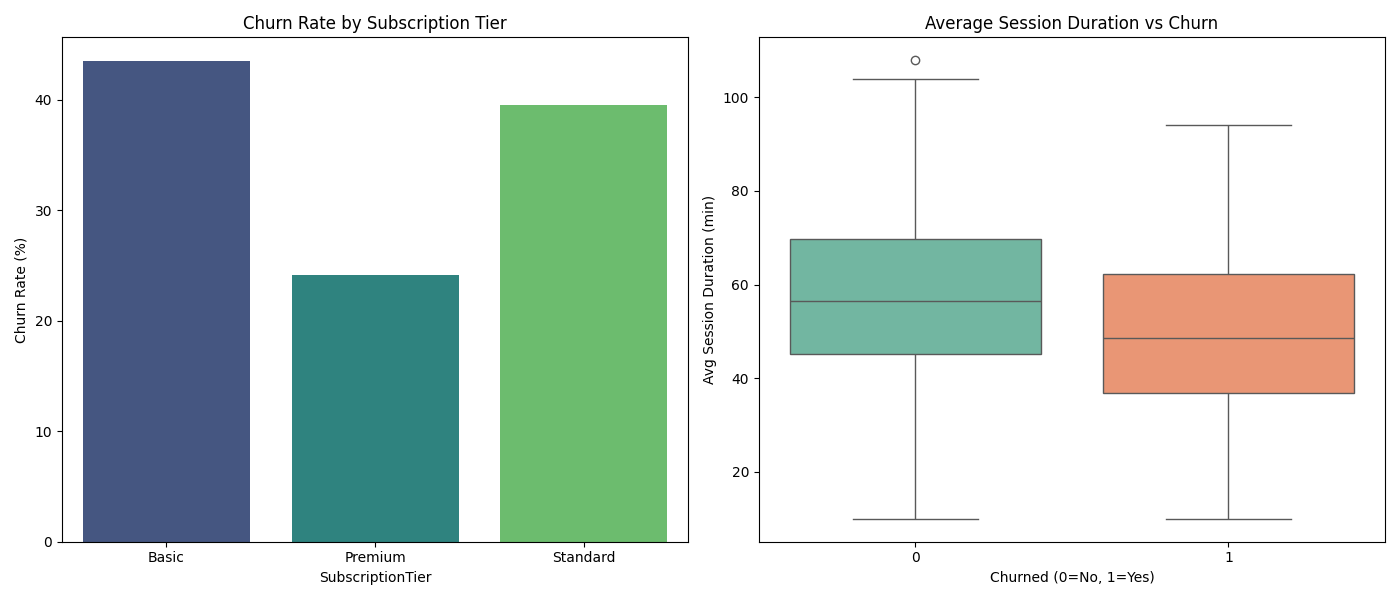

churn_summary.png


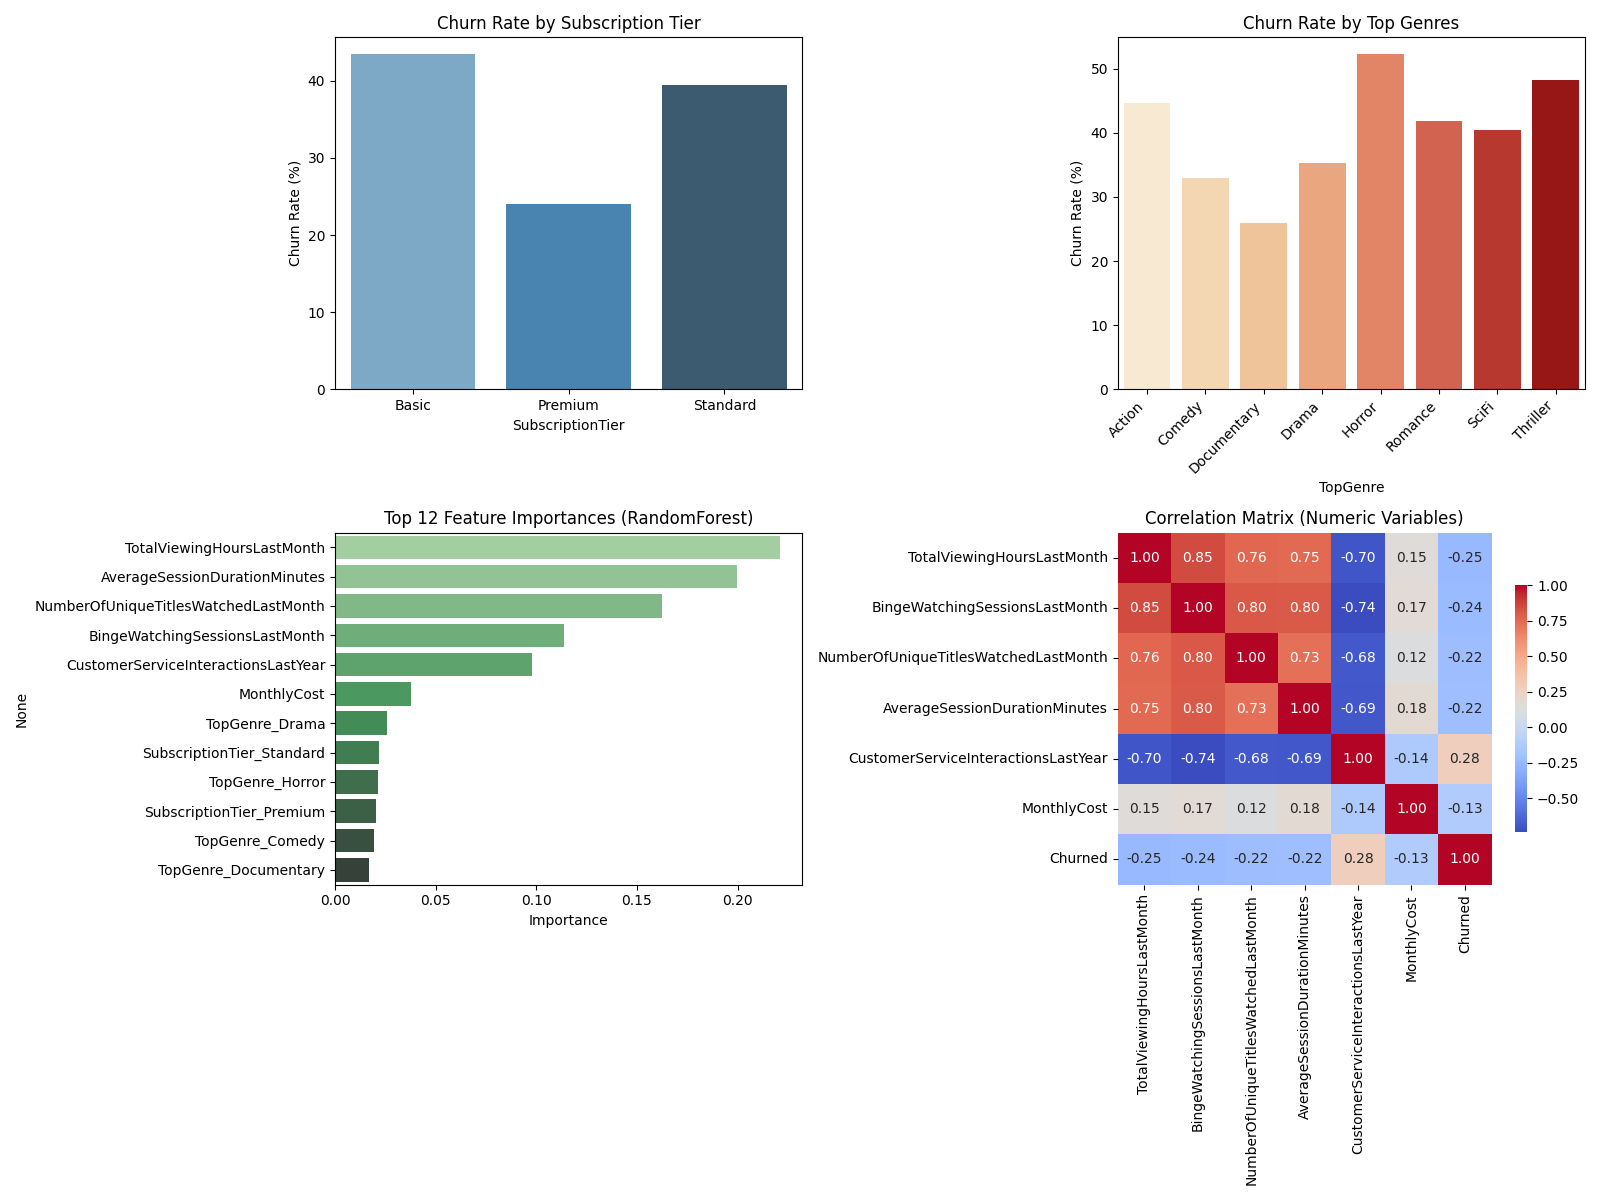

In [19]:
file_metadata = upload("streaming.csv")
filename = stage_file(file_metadata.id)

messages = []
add_user_message(
    messages,
    f"""
Run a detailed analysis to determine major drivers of churn.
The data is in the file '{filename}' in the current directory.
Your final output should include at least one detailed plot summarizing your findings.

Critical note: Every time you execute code, you're starting with a completely clean slate.
No variables or library imports from previous executions exist. You need to redeclare/reimport all variables/libraries.

Start by inspecting the columns and data types before analysing.
""",
)

response = run_code_agent(messages)
display(Markdown(text_from_message(response)))
show_plots()